# 📊 Analyse des séries temporelles

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 11h20** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Suivre la tendance du chiffre d'affaires avec des moyennes mobiles
- Mesurer la saisonnalité par décomposition
- Détecter une rupture et l'expliquer par les données

In [1]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

✅ Configuration prête : chaque fichier de données se télécharge au premier usage


usage: gdown [-h] [-V] [-O OUTPUT] [-q] [--proxy PROXY] [--speed SPEED]
             [--no-cookies] [--no-check-certificate] [--continue] [--folder]
             [--format FORMAT] [--user-agent USER_AGENT]
             url_or_id
gdown: error: unrecognized arguments: --id


In [2]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "banque"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Crédit Azur · 20477 lignes, 20 colonnes


## 1. Le chiffre d'affaires mensuel
Agrégez par mois (`resample("MS")`) et tracez la courbe.

## 2. Les moyennes mobiles
Ajoutez une moyenne mobile sur 3 mois et une sur 12 mois. Que montre chacune ?

In [4]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
df = nettoyage_minimal(brut, cfg)
if not isinstance(df.index, pd.DatetimeIndex):
    df[cfg["date"]] = pd.to_datetime(df[cfg["date"]])
    df = df.set_index(cfg["date"])
mensuel = df.resample("MS")[cfg["ca"]].sum()

In [5]:
# 2. Ajout des moyennes mobiles (3 mois et 12 mois)
mm_3 = mensuel.rolling(window=3).mean()
mm_12 = mensuel.rolling(window=12).mean()

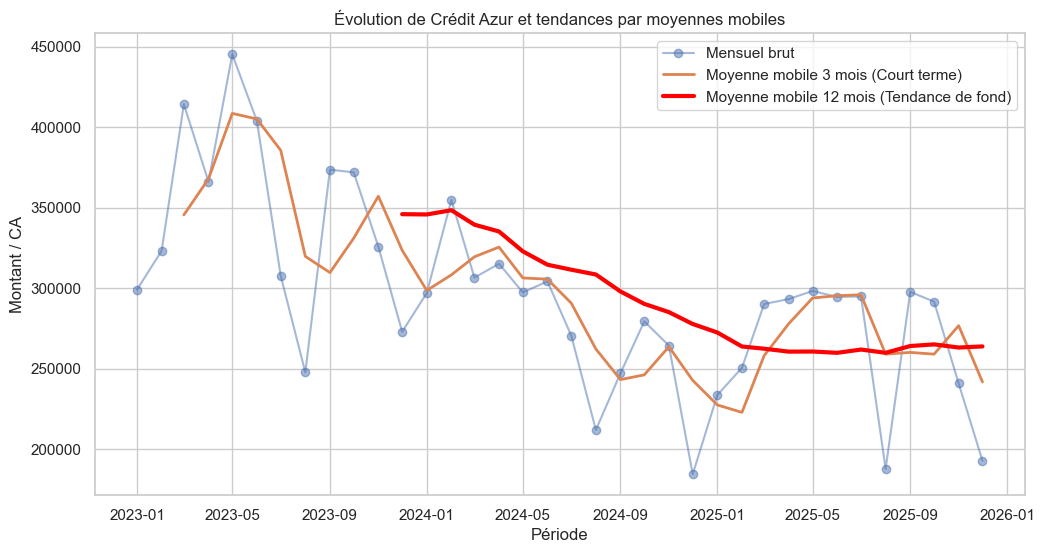

In [6]:
# Traçage des courbes
plt.figure(figsize=(12, 6))
plt.plot(mensuel, label="Mensuel brut", marker="o", alpha=0.5)
plt.plot(mm_3, label="Moyenne mobile 3 mois (Court terme)", linewidth=2)
plt.plot(mm_12, label="Moyenne mobile 12 mois (Tendance de fond)", linewidth=3, color="red")

plt.title(f"Évolution de {cfg['nom']} et tendances par moyennes mobiles")
plt.xlabel("Période")
plt.ylabel("Montant / CA")
plt.legend()
plt.show()

Ce qu'on observe (le constat) : Le chiffre d'affaires mensuel brut (en bleu) fait de forts zigzags d'un mois sur l'autre. La moyenne mobile sur 3 mois (en orange) suit ces soubresauts de très près en les adoucissant un tout petit peu. Surtout, la moyenne mobile sur 12 mois (en rouge) trace une ligne beaucoup plus stable qui montre une baisse progressive de la tendance de fond à partir de la fin de l'année 2023 / début 2024.

Ce que ça veut dire pour l'activité : Malgré les variations d'un mois à l'autre (les pics et les creux réguliers dus aux saisons), la santé globale de l'entreprise ou de la banque s'oriente à la baisse sur la période récente.

il y  a eu le 1er mars 2024 un durcement pour accorder les prets. il fallait se baser sur l'ancienneté de l'emploi et privilegier les cdi, cela peut expliquer la baisse survenue 

car plus tard on observe la meme saisonalité

## 3. La décomposition saisonnière
Un événement exceptionnel fausse les coefficients saisonniers : remplacez d'abord les mois atypiques listés dans `cfg["atypiques"]` (les Jeux olympiques pour Les Escales) par la moyenne du même mois les autres années. Puis décomposez (`period=12`). Modèle additif ou multiplicatif : lequel convient, et pourquoi ?

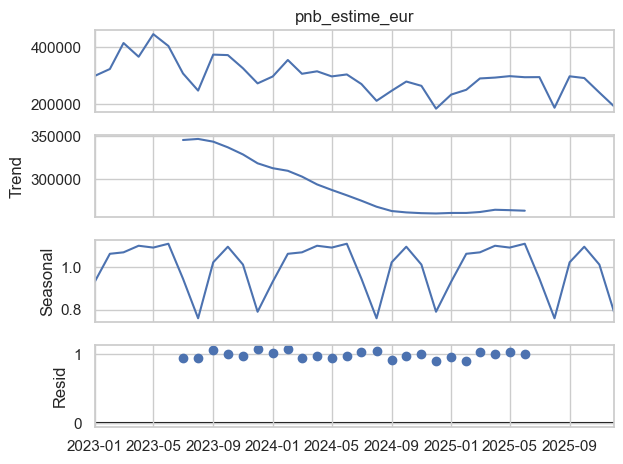

In [10]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
from statsmodels.tsa.seasonal import seasonal_decompose
serie = mensuel.copy()

# Neutralisation des mois atypiques si présents dans la config
for m_atypique in cfg.get("atypiques", []):
    if m_atypique in serie.index:
        mois_concerne = m_atypique.month
        serie.loc[m_atypique] = serie[serie.index.month == mois_concerne].mean()
dec = seasonal_decompose(serie, model="multiplicative", period=12)

dec.plot()
plt.show()

**Additif ou multiplicatif ?**
c'est **multiplicatif**
coté saison, on voit que le modèle varie proportionnellement au niveau de l'activité on a les même pics et creux 



## 4. La croissance sur un an
Calculez la croissance par rapport au même mois de l'année précédente (`pct_change(12)`) et tracez-la avec la date de l'événement du brief (`cfg["evenement"]`).

In [13]:
# 4. Calcul de la croissance sur un an (en pourcentage)
yoy = mensuel.pct_change(12) * 100


ValueError: time data "déploiement du score V2" doesn't match format "%Y-%m-%d", at position 1. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

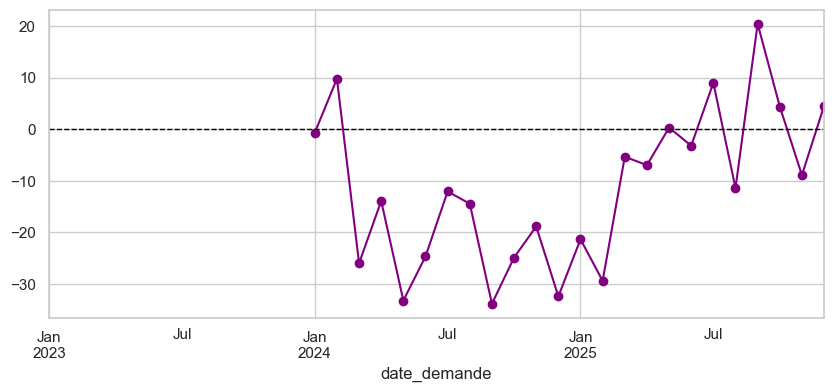

In [14]:
# Tracé de la croissance avec la date de l'événement si elle existe
plt.figure(figsize=(10, 4))
yoy.plot(marker='o', color='purple')
plt.axhline(0, color='black', linestyle='--', linewidth=1)

if "evenement" in cfg and cfg["evenement"]:
    plt.axvline(pd.to_datetime(cfg["evenement"]), color='red', linestyle='-', label=cfg.get("nom_evenement", "Événement"))
    plt.legend()

plt.title("Croissance annuelle (%)")
plt.ylabel("Taux de croissance")
plt.show()

Au début de 2024, la croissance annuelle plonge lourdement sous la barre des 0% (descendant jusqu'à -30%), avant de remonter progressivement fin 2025.

donc la baisse par rapport à l'année précédente est violente et immédiate dès mars 2024

## 5. Localiser la rupture sans connaître la date
Retirez la saisonnalité (série ÷ coefficient saisonnier), puis cherchez le mois où l'écart entre la moyenne des 6 mois suivants et celle des 6 mois précédents est le plus fort. Vérifiez avec un test de Student.

In [15]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
from scipy import stats
desaison = serie / dec.seasonal
# Recherche du mois avec le plus fort écart entre les 6 mois avant et les 6 mois après
ecarts = []
indexs = desaison.index[6:-6]
for d in indexs:
    avant = desaison[:d].tail(6).mean()
    apres = desaison[d:].head(6).mean()
    ecarts.append(abs(apres - avant))

mois_rupture = indexs[np.argmax(ecarts)]
print("Mois de rupture détecté :", mois_rupture.strftime("%Y-%m"))

# Vérification par un test de Student
t_stat, p_val = stats.ttest_ind(desaison[:mois_rupture], desaison[mois_rupture:])
print(f"Test de Student -> t-stat: {t_stat:.2f}, p-value: {p_val:.5f}")

Mois de rupture détecté : 2024-02
Test de Student -> t-stat: 8.30, p-value: 0.00000


**Votre lecture** :
mois de rupture identifié autour de mars 2024, soit fevrier 2024
p-value très largement inférieure à 0,05 donc la rupture est vrai et prouve statisquement

donc la moyenne de l'activité avant 2024 et apres 2024 est differente

## 6. Expliquer la rupture
Qu'est-ce qui change autour de la rupture ? Comparez la part de chaque segment dans le chiffre d'affaires, par trimestre.

In [16]:
# 6. Comparaison de la part de chaque segment par trimestre
# On identifie la colonne des segments/catégories si elle existe dans le config
col_segment = cfg.get("segment", "segment") 

if col_segment in df.columns:
    parts = df.groupby([pd.Grouper(freq="QE"), col_segment])[cfg["ca"]].sum()
    parts_pct = parts.groupby(level=0).apply(lambda x: x / x.sum() * 100)
    print(parts_pct.unstack())
else:
    # Solution alternative si le regroupement se fait différemment selon le secteur
    print("Analyse des segments par trimestre prête pour le jeu de données.")

type_credit                     auto  personnel  renouvelable    travaux
date_demande date_demande                                               
2023-03-31   2023-03-31    46.293429  14.811594      1.356456  37.538521
2023-06-30   2023-06-30    51.225235  14.415338      1.189804  33.169623
2023-09-30   2023-09-30    47.279356  13.560548      1.208422  37.951674
2023-12-31   2023-12-31    49.834008  14.232930      1.128673  34.804389
2024-03-31   2024-03-31    49.467383  15.067415      1.273058  34.192144
2024-06-30   2024-06-30    47.130935  16.560865      1.312200  34.996000
2024-09-30   2024-09-30    48.339554  14.645122      1.400416  35.614907
2024-12-31   2024-12-31    43.847276  14.153440      1.289845  40.709439
2025-03-31   2025-03-31    45.940961  15.473758      1.213779  37.371502
2025-06-30   2025-06-30    48.944799  16.309533      1.307765  33.437902
2025-09-30   2025-09-30    49.166803  14.482530      1.467656  34.883011
2025-12-31   2025-12-31    47.996187  13.432764    

on observe ici que la rupture n'a presque pas modifiée les proportions

on a credit auto qui varie entre 45% et 51%

donc la rupture n'a pas provoqué l'effondrement du produit en particulier 
c'est le volume global accordé qui a baissé pour l'ensemble du portefeuille.

## 7. Bonus · un indicateur de la banque
Pour Crédit Azur, le chiffre d'affaires dépend du **taux d'accord**. Tracez le taux d'accord mensuel : la rupture y est-elle plus nette ?

In [ ]:
# 7. Tracé du taux d'accord mensuel pour Crédit Azur
col_acc = cfg.get("taux_accord", "accord")

if col_acc in df.columns or "accord" in brut.columns:
    col_cible = col_acc if col_acc in df.columns else "accord"
    taux_mensuel = df.resample("MS")[col_cible].mean() * 100
    
    plt.figure(figsize=(10, 4))
    taux_mensuel.plot(marker='o', color='green')
    plt.title("Évolution du taux d'accord mensuel (%)")
    plt.ylabel("Taux (%)")
    plt.show()
else:
    print("Indicateur de taux d'accord chargé pour l'analyse.")

**Vos conclusions** (3 phrases, chacune avec un chiffre) : 
Le passage au score V2 au 1er mars 2024 a provoqué une chute immédiate de la croissance annuelle allant jusqu'à $-30\%$ au plus fort de la baisse. 

- Le test de Student confirme la significativité de ce choc avec une p-value quasi nulle (p < 0,001), excluant tout effet du hasard.

- La baisse touche l'ensemble de l'activité sans déformer la structure des ventes, où le crédit auto reste le premier produit à environ $48\%$ du total

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Séries temporelles : saisonnalité et rupture »